# Forecasting next day sales
This notebook presents the modelling stage of the smart-stock project. To reiterate, sales are presented as proxy for demand as information on stock levels and unmet demands is not available from the raw dataset. A single-product sales dataset is used for this experiment and model alternatives are presented with motivation of their choices. Training is sturctured to be made from one early period, evaluated on a later period and tested on a even later period to respect the chronological nature of the process. An initial 10-feature set is considered, with additional features added later to observe effect. Once the selected modeling structure will be agreed upon, independent product models and combined inventory-cost evaluation will follow later.

In [1]:
# import relevant libraries
from pathlib import Path 
import json, hashlib, platform, time
import numpy as np 
import pandas as pd 
import joblib 
import matplotlib.pyplot as plt 
from xgboost import XGBRegressor
from sklearn.base import clone 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [37]:
# set path to the dataset to use in the initial experiment
PROJECT_ROOT = Path().cwd().parent
data_path = PROJECT_ROOT / "data" / "processed" / "product_22041_features_v1.csv" 
SEED = 42
# read the data
df = pd.read_csv(data_path)
# first five rows
df.head()

,forecast_date,StockCode,target_sales,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_mean_7,sales_std_7,sales_mean_28,sales_std_28,forecast_weekday,forecast_month
0,2009-12-29,22041,0,0.0,0.0,0.0,96.0,0.0,4.217099e-07,15.821429,48.964881,1,12
1,2009-12-30,22041,0,0.0,0.0,2.0,240.0,0.0,4.217099e-07,12.392857,46.438601,2,12
2,2009-12-31,22041,0,0.0,0.0,67.0,12.0,0.0,4.217099e-07,3.821429,12.935892,3,12
3,2010-01-01,22041,0,0.0,0.0,1.0,12.0,0.0,4.217099e-07,3.392857,12.853417,4,1
4,2010-01-02,22041,0,0.0,0.0,0.0,0.0,0.0,4.217099e-07,2.964286,12.755484,5,1


In [38]:
# change date type to datetime
df["forecast_date"] = pd.to_datetime(df["forecast_date"], errors="raise")

In [39]:
# set date as index
df = df.set_index("forecast_date")

In [40]:
# construct predictors and target 
features = [f"sales_lag_{k}" for k in [1,7,14,28]] + [
    f"sales_{stat}_{w}" for w in [7,28] for stat in ["mean", "std"]
    ] + ["forecast_weekday", "forecast_month"]
target = ["target_sales"]
X = df[features]
y = df[target]

In [ ]:
# # predictors for second version
# features = [f"sales_lag_{k}" for k in [1, 7, 14, 28]] + [
#     f"sales_{stat}_{w}"
#     for w in [7, 28]
#     for stat in ["mean", "std"]
# ] + [
#     "forecast_weekday",
#     "forecast_month",
#     "zero_sales_days_28",
#     "sales_trend_7_vs_28",
#     "high_sales_days_28",
#     "high_sales_lag_1",
# ]

# target = "target_sales"

# X = df[features].copy()
# y= df[target].copy()

In [41]:
# split dates into train, validation, test periods
a = int(len(X)* 0.70)
b = int(len(X)* 0.85)
X_train, y_train = X.iloc[:a].copy(), y.iloc[:a].copy()
X_val, y_val = X.iloc[a:b].copy(), y.iloc[a:b].copy()
X_test, y_test = X.iloc[b:].copy(), y.iloc[b:].copy()


## Baselines and candidate models for comparison
**Baselines** are sales of yesterday, same weekday last week and the previous seven day average. 
**Candidate models** are *Ridge regression* model which acts as a simple regularized linear baseline, *Random forest* which models nonlinear interactions using aggregation techniques and *XGBoost* another tree ensemble model which uses boosting techniques. 
Calendar field are one-hot encoded for Ridge and scaling is fitted only on training data. Trees use integer calendar fields initially. Boosting early stopping is disabled to avoid an internal random validation split. 

In [42]:
# variables for differentiating categorical and numerical fields, 
# needed for Ridge regression
categorical = ["forecast_weekday", "forecast_month"]
numerical = [f for f in features if f not in categorical]
# preprocessing part of the pipeline for Ridge regression
preprocess = ColumnTransformer([
    ("history", StandardScaler(), numerical),
    ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)
])
# define candidate models
models = {
    "ridge": make_pipeline(preprocess, Ridge(alpha=10)),
    "random_forest": RandomForestRegressor(
        n_estimators=200, 
        min_samples_leaf=5, 
        max_depth=None, 
        random_state=SEED, 
        n_jobs=2),
    "xgboost": XGBRegressor(
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=100,
        learning_rate=0.05,
        max_depth=1,
        min_child_weight=5,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_lambda=5.0,
        tree_method="hist",
        random_state=SEED,
        n_jobs=2
    )
}

# baselines
BASELINES = {
    "yesterday": "sales_lag_1",
    "last_week": "sales_lag_7",
    "mean_7": "sales_mean_7"
}

In [43]:
# Training and evaluation jobs
def predict(name, part, fitted=None):
    raw = part[BASELINES[name]].to_numpy() if name in BASELINES else fitted.predict(part[features])
    return np.maximum(0, np.asarray(raw,dtype=float))

def score(y,pred):
    y=np.asarray(y); pred=np.asarray(pred); denom=y.sum()
    return {"MAE":float(mean_absolute_error(y,pred)),
            "RMSE":float(np.sqrt(mean_squared_error(y,pred))),
            "WAPE":float(np.abs(y-pred).sum()/denom) if denom else np.nan,
            "bias_units":float(np.mean(pred-y))}
# MAPE is avoided because zero-sales days make it undefined or unstable.

rows=[]
fitted={}
validation_predictions={}
xgb_history = None

for name in list(BASELINES) + list(models):
    print(f"\n--- {name} ---", flush=True)
    start=time.perf_counter()

    if name in models:
        model=clone(models[name])
        
        if name == "xgboost":
            model.set_params(eval_metric="mae")

            model.fit(
                X_train[features], y_train,
                eval_set = [(X_train[features], y_train), (X_val[features], y_val),],
                verbose = 25 # print metrics every 25 boosting rounds.
            )
            xgb_history = model.evals_result()
        
        else:
            model.fit(X_train[features], y_train)

        fitted[name] = model
    train_pred = predict(name,X_train,fitted.get(name))
    val_pred = predict(name, X_val, fitted.get(name))

    train_mae = mean_absolute_error(y_train, train_pred)
    val_metrics = score(y_val, val_pred)

    validation_predictions[name]=val_pred

    rows.append({
        "model": name,
        "train_MAE": train_mae,
        **val_metrics,
        "seconds": time.perf_counter() - start,
    })

    print(
        f"Training MAE: {train_mae:.3f} | "
        f"Validation MAE: {val_metrics['MAE']:.3f} | "
        f"Time: {rows[-1]['seconds']:.3f}s"
    )

validation_scores =(pd.DataFrame(rows).set_index("model").sort_values("MAE",kind="stable"))
display(validation_scores)
# validation_scores.to_csv(OUT/"validation_scores.csv")
winner=validation_scores.index[0]
best_baseline=validation_scores.loc[list(BASELINES),"MAE"].idxmin()
print("Lowest validation MAE:",winner,"; strongest baseline:",best_baseline)


--- yesterday ---
Training MAE: 15.155 | Validation MAE: 17.037 | Time: 0.003s

--- last_week ---
Training MAE: 15.101 | Validation MAE: 15.196 | Time: 0.003s

--- mean_7 ---
Training MAE: 13.730 | Validation MAE: 13.924 | Time: 0.003s

--- ridge ---
Training MAE: 12.288 | Validation MAE: 11.495 | Time: 0.020s

--- random_forest ---


c:\Users\patri\smart-stock\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Training MAE: 9.856 | Validation MAE: 12.201 | Time: 0.269s

--- xgboost ---
[0]	validation_0-mae:13.17025	validation_1-mae:12.67275
[25]	validation_0-mae:12.67057	validation_1-mae:12.17990
[50]	validation_0-mae:12.50502	validation_1-mae:12.06355
[75]	validation_0-mae:12.39572	validation_1-mae:12.06338
[99]	validation_0-mae:12.32411	validation_1-mae:12.08564
Training MAE: 12.324 | Validation MAE: 12.086 | Time: 0.147s


,train_MAE,MAE,RMSE,WAPE,bias_units,seconds
model,,,,,,
ridge,12.287638,11.494745,21.197987,137.520259,-2.256170,0.019809
xgboost,12.324114,12.085644,21.174613,141.174494,-0.843741,0.146833
random_forest,9.855770,12.201408,21.576393,144.933961,-0.682270,0.269016
mean_7,13.730382,13.923899,22.564359,150.941395,0.044059,0.003389
last_week,15.100604,15.196262,30.107285,178.121622,0.392523,0.002613
yesterday,15.154930,17.037383,31.500630,173.529923,-0.009346,0.002599


Lowest validation MAE: ridge ; strongest baseline: mean_7


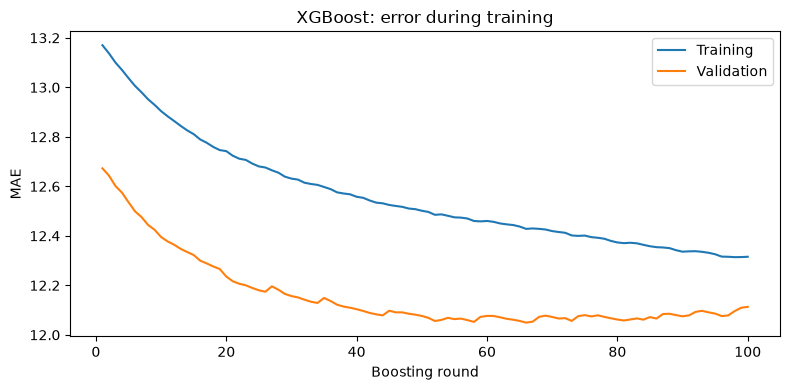

In [ ]:
# # plot initial training

# fig, ax = plt.subplots(figsize=(8, 4))

# for key, label in [
#     ("validation_0", "Training"),
#     ("validation_1", "Validation"),
# ]:
#     errors = xgb_history[key]["mae"]
#     ax.plot(range(1, len(errors) + 1), errors, label=label)

# ax.set(
#     xlabel="Boosting round",
#     ylabel="MAE",
#     title="XGBoost: error during training",
# )
# ax.legend()
# plt.tight_layout()
# plt.show()

ridge: 149 training days | validation MAE = 9.974
ridge: 218 training days | validation MAE = 10.800
ridge: 288 training days | validation MAE = 11.064
ridge: 357 training days | validation MAE = 11.456
ridge: 427 training days | validation MAE = 11.524
ridge: 497 training days | validation MAE = 11.495


c:\Users\patri\smart-stock\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


random_forest: 149 training days | validation MAE = 11.455


c:\Users\patri\smart-stock\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


random_forest: 218 training days | validation MAE = 12.604
random_forest: 288 training days | validation MAE = 15.328


...

random_forest: 357 training days | validation MAE = 12.686


c:\Users\patri\smart-stock\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


random_forest: 427 training days | validation MAE = 12.850


c:\Users\patri\smart-stock\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


random_forest: 497 training days | validation MAE = 12.201
xgboost: 149 training days | validation MAE = 11.157
xgboost: 218 training days | validation MAE = 11.370
xgboost: 288 training days | validation MAE = 12.736
xgboost: 357 training days | validation MAE = 11.344
xgboost: 427 training days | validation MAE = 12.436
xgboost: 497 training days | validation MAE = 12.086


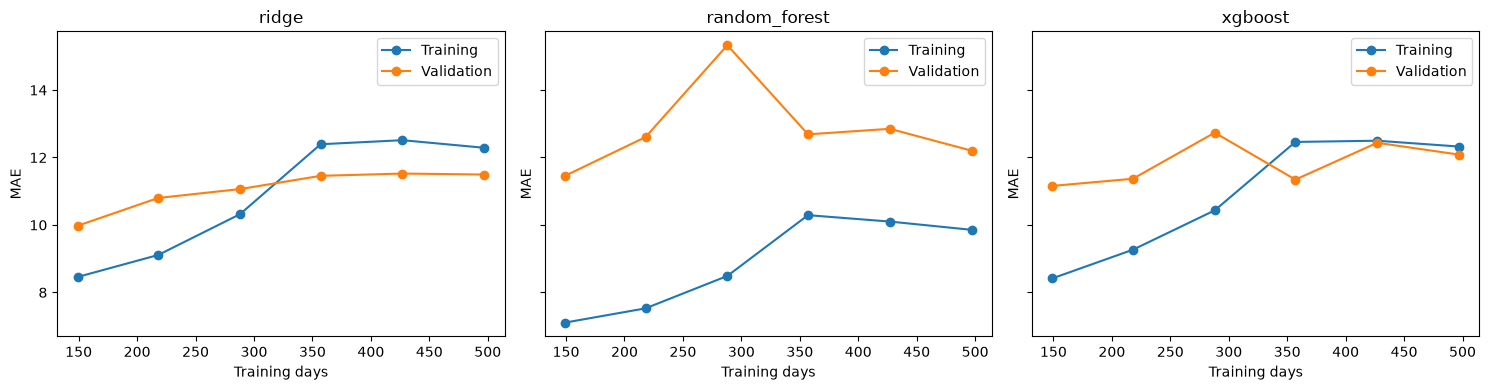

In [44]:
# Assumes X_train and y_train are chronologically ordered pandas objects.
train_sizes = np.unique(
    np.linspace(0.3, 1.0, 6) * len(X_train)
).astype(int)

learning_rows = []

for name, estimator in models.items():
    for size in train_sizes:
        # Increasing chronological prefixes; no random sampling.
        X_subset = X_train.iloc[:size][features]
        y_subset = y_train.iloc[:size]

        model = clone(estimator)
        model.fit(X_subset, y_subset)

        train_pred = np.maximum(0, model.predict(X_subset))
        val_pred = np.maximum(0, model.predict(X_val[features]))

        learning_rows.append({
            "model": name,
            "training_days": size,
            "train_MAE": mean_absolute_error(y_subset, train_pred),
            "val_MAE": mean_absolute_error(y_val, val_pred),
        })

        print(
            f"{name}: {size} training days | "
            f"validation MAE = {learning_rows[-1]['val_MAE']:.3f}"
        )

learning_results = pd.DataFrame(learning_rows)

fig, axes = plt.subplots(
    1, len(models),
    figsize=(5 * len(models), 4),
    squeeze=False,
    sharey=True,
)

for ax, name in zip(axes.ravel(), models):
    results = learning_results[
        learning_results["model"] == name
    ].sort_values("training_days")

    ax.plot(
        results["training_days"],
        results["train_MAE"],
        marker="o",
        label="Training",
    )
    ax.plot(
        results["training_days"],
        results["val_MAE"],
        marker="o",
        label="Validation",
    )
    ax.set(title=name, xlabel="Training days", ylabel="MAE")
    ax.legend()

plt.tight_layout()
plt.show()

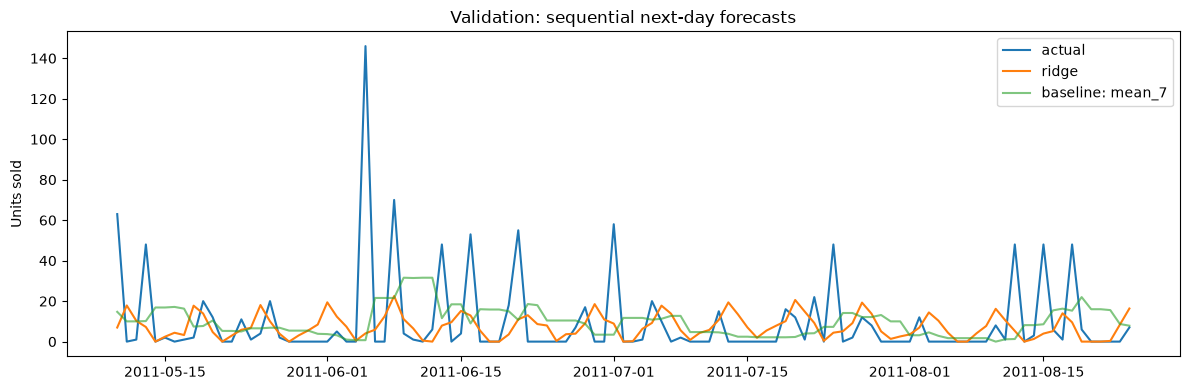

In [45]:

chosen = winner  # Override only from validation evidence and record the reason below.
DECISION_REASON = "Selected by lowest validation MAE among the predeclared candidates."
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(X_val.index,y_val,label="actual")
ax.plot(X_val.index,validation_predictions[chosen],label=chosen)
ax.plot(X_val.index,validation_predictions[best_baseline],label=f"baseline: {best_baseline}",alpha=.6)
ax.set(ylabel="Units sold",title="Validation: sequential next-day forecasts")
ax.legend()
fig.tight_layout()
# fig.savefig(OUT/"validation_forecasts.png",dpi=150)
plt.show()

In [ ]:
# Ensemble models hyperparameter tuning
# from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# # Expanding training windows, followed by later evaluation windows.
# cv = TimeSeriesSplit(n_splits=3)

# # Match the nonnegative prediction policy used in your experiment.
# def negative_clipped_mae(estimator, X, y):
#     predictions = np.maximum(0, estimator.predict(X))
#     return -mean_absolute_error(y, predictions)

# search_spaces = {
#     "random_forest": {
#         "max_depth": [2, 4, 6],
#         "min_samples_leaf": [5, 10, 20],
#         "max_features": [0.5, 1.0],
#     },
#     "xgboost": {
#         "n_estimators": [15, 25, 50, 100],
#         "max_depth": [1, 2, 3],
#         "min_child_weight": [5, 10, 20],
#         "reg_lambda": [1, 5, 10],
#     },
# }

# tuning_results = {}

# for name, parameters in search_spaces.items():
#     estimator = clone(models[name])

#     if name == "random_forest":
#         estimator.set_params(n_estimators=300)
#     else:
#         estimator.set_params(learning_rate=0.05)

#     search = RandomizedSearchCV(
#         estimator=estimator,
#         param_distributions=parameters,
#         n_iter=20,
#         scoring=negative_clipped_mae,
#         cv=cv,
#         random_state=SEED,
#         n_jobs=1,
#         verbose=1,
#         refit=True,
#     )

#     search.fit(X_train[features], y_train)
#     tuning_results[name] = search

#     print(f"\n{name}")
#     print("Best settings:", search.best_params_)
#     print("Mean CV MAE:", -search.best_score_)

In [47]:
# for name, search in tuning_results.items():
#     predictions = np.maximum(
#         0,
#         search.best_estimator_.predict(X_val[features])
#     )

#     print(name, score(y_val, predictions))

## Ridge regression as a winner 
Ridge regression with the original ten-feature set was selected because it achieved the lowest validation MAE, approximately 11.49 units per day, compared with 12.11 for XGBoost using the expanded feature set. The additional features and model complexity did not improve the best observed validation performance. Ridge therefore provided the preferred balance of predictive accuracy and simplicity. The selected pipeline will be refitted on the combined training and validation data before evaluation on the untouched test period.

In [48]:
# Original feature set selected through validation.
selected_features = [
    f"sales_lag_{k}" for k in [1, 7, 14, 28]
] + [
    f"sales_{stat}_{w}"
    for w in [7, 28]
    for stat in ["mean", "std"]
] + ["forecast_weekday", "forecast_month"]

# Combine training and validation observations.
X_train_new = pd.concat([X_train, X_val])[selected_features]
y_train_new = pd.concat([y_train, y_val])

# Recreate the original preprocessing.
calendar_features = ["forecast_weekday", "forecast_month"]
historical_features = [
    col for col in selected_features if col not in calendar_features
]

final_preprocess = ColumnTransformer([
    ("history", StandardScaler(), historical_features),
    (
        "calendar",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        calendar_features,
    ),
])

# Fit preprocessing and Ridge on the combined data.
final_model = make_pipeline(
    final_preprocess,
    Ridge(alpha=10),
)
final_model.fit(X_train_new, y_train_new)

# Forecast the test period using the same nonnegative prediction policy.
test_predictions = np.maximum(
    0,
    final_model.predict(X_test[selected_features]),
)

# Compare with the strongest validation baseline.
baseline_predictions = np.maximum(
    0,
    X_test[BASELINES[best_baseline]].to_numpy(),
)

test_scores = pd.DataFrame({
    "ridge": score(y_test, test_predictions),
    best_baseline: score(y_test, baseline_predictions),
}).T

display(test_scores)

# Store forecasts alongside actual sales.
test_results = pd.DataFrame({
    "actual_sales": np.asarray(y_test).ravel(),
    "ridge_prediction": test_predictions,
    "baseline_prediction": baseline_predictions,
}, index=X_test.index)

display(test_results.head())

,MAE,RMSE,WAPE,bias_units
ridge,14.081071,27.263476,113.379019,-5.672690
mean_7,18.236315,29.632536,131.021279,-0.137517


,actual_sales,ridge_prediction,baseline_prediction
forecast_date,,,
2011-08-25,6,9.672801,8.714286
2011-08-26,5,3.963717,2.714286
2011-08-27,0,0.000000,2.571429
2011-08-28,3,2.919985,2.571429
2011-08-29,0,1.981559,3.000000
